# How to Access OBS Channel Data 

This notebook should help with understanding how the Dataset, Station, and Channel classes interact with each other in order to analyze seismic data from an OBS experiment. The first half will detail this, and the second half will be used to test how the instrument response is being applied. 

Do you have the right dependencies to run this code? This code was built using the `seis` conda environment from Matoza's Earth 232. Here is how you can create the same env if you need it: 

```
conda create -n seis obspy cartopy pytest pytest-json anaconda
conda activate seis
```

In [1]:
# create interactive matplotlib plots
%load_ext autoreload
%autoreload 2
%matplotlib widget

# work from the lobster repo 
import os
os.chdir("/Users/nico/Documents/UCSB/research/LOBSTER")

# LOBSTER imports
from lobster_python import Dataset
from lobster_python.hdf5.hdf5_io import *
from lobster_python.processing.response import *
from lobster_python.processing.psd import *

# obspy, numpy, matplotlib imports
from obspy import UTCDateTime, read_inventory, read
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# create example Pacific ORCA dataset 

dataset = Dataset(
    name="DemoORCA",
    data_dir="/Users/nico/Documents/UCSB/research/ORCA/DemoORCA",
    response_dir="/Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP",
    metadata_file="/Users/nico/Documents/UCSB/research/LOBSTER/examples/mockORCA/mockORCAdb.csv"
)

# Discover data and construct objects
dataset.scan()

# python class attributes are accessed like so: class.attribute 
# specific instances of the attribute are accessed with the attribute name: class.attribute['name']

# here is an example of what is in this mock dataset
print(f"Here are the stations within this mock dataset: {dataset.stations.keys()}")

# the dataset contains all the stations, within each station are the channels
print(f"Here are the channels within the station MM04: {dataset.stations['MM04'].channels.keys()}")

Here are the stations within this mock dataset: dict_keys(['MM04', 'MM05', 'MM06', 'MM07', 'MM08', 'MM09'])
Here are the channels within the station MM04: dict_keys(['CH0', 'CH1', 'CH3', 'CH2'])


Luckily, the `Dataset` class has some built in functions so you can access stations and channels in a more legible format:

In [3]:
# easier way to access a single station, and the channels within it!
station = dataset.get_station("MM04")
print(f"Here are the channels in MM04:", station.list_channels())

# easier way to access a specific channel in a give station
channel = station.get_channel("CH0")

print("Number of waveform files for CH0:", channel.n_waveforms)
print("Instrument Response File:", channel.response_file)

Here are the channels in MM04: ['CH0', 'CH1', 'CH2', 'CH3']
Number of waveform files for CH0: 371
Instrument Response File: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH0/RESP.P2.MM04..CH0


Waveform files are within each `Channel` object in a `Station' object, and follow the given file syntax: 

```
…/ORCA/DemoORCA/MM04.CH1.2020.080.00.30.59.msd
…/main_repo/data_repo/station.channelcode.year.julianday.hour.minute.second.msd
```

So if we give a specific station and channel along with the dates of interest, we can access the waveform files and do what we want with it. 
Luckily we have a function for this within the channel class, here is an example:


Channel Response
	From M/S (Velocity in Meters per Second) to V (Volts)
	Overall Sensitivity: 1.45973e+09 defined at 0.200 Hz
	1 stages:
		Stage 1: PolesZerosResponseStage from M/S to V, gain: UNKNOWN
Source            Last Sample                 Next Sample                 Delta           Samples 
Total: 0 gap(s) and 0 overlap(s)

  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.



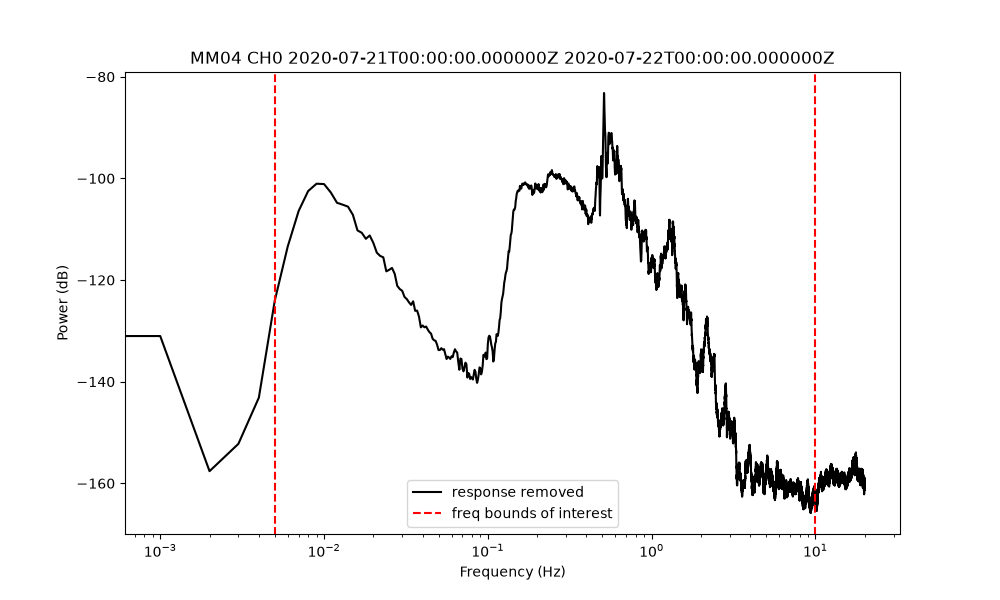

In [15]:
# dates are expected to be UTCDateTime! 

# this the range of days data will be fetched for:
start_date = UTCDateTime("2020-07-20")
end_date = UTCDateTime("2020-07-25")

# for this example, we will look at a day within the range of days from above
day_start_date = UTCDateTime("2020-07-21")
day_end_date = UTCDateTime("2020-07-22")

station = dataset.get_station("MM04")
channel = station.get_channel("CH0")
inventory = read_inventory(str(channel.response_file),format="RESP")

print(inventory.get_response("XX.EE04.XX.CH0",day_start_date))


# function to identify files
waveform_files = channel.get_waveform_files(
        starttime=start_date,
        endtime=end_date
    )

# create Obspy Stream object and merge the datasets
stream = read(waveform_files[0])
for file in waveform_files[1:]:
    stream += read(file)
    stream.merge(method=0, fill_value=None) # add some safety precautions here
    trace = stream[0]

stream.print_gaps() # use this to identify gaps in the data
day_of_data = extract_time_window(trace,starttime=day_start_date,endtime=day_end_date) 

# demean, detrend, and remove instrument response
day_of_data.detrend(type="demean")
day_of_data.detrend(type="linear")
day_of_data = remove_response(day_of_data.copy(),inventory=inventory)

psd = calculate_psd(day_of_data,sampling_rate=day_of_data.stats.sampling_rate)
psd_in_db = 10*np.log10(psd[1])

data = day_of_data.data
times = day_of_data.times("matplotlib")


plt.figure(figsize=(10,6))
plt.title(f"MM04 CH0 {str(day_start_date)} {str(day_end_date)}")
plt.semilogx(psd[0],psd_in_db,c='black',label='response removed')
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.axvline(x=0.005,ymin=-100,ymax=100,c='red',linestyle='--')
plt.axvline(x=10,ymin=-100,ymax=100,label='freq bounds of interest',c='red',linestyle='--')
plt.legend()
plt.show()


## Loop over Multiple days per channel

Here is an example workflow of identifying a station of interest, days of interest, and channels of interest. The user can then generate multiple PSDs per hour (11 10 minute windows w/ 5 minute overlap), calculate the hourly median, and plot. 


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


  - station: waveform='MM04', R

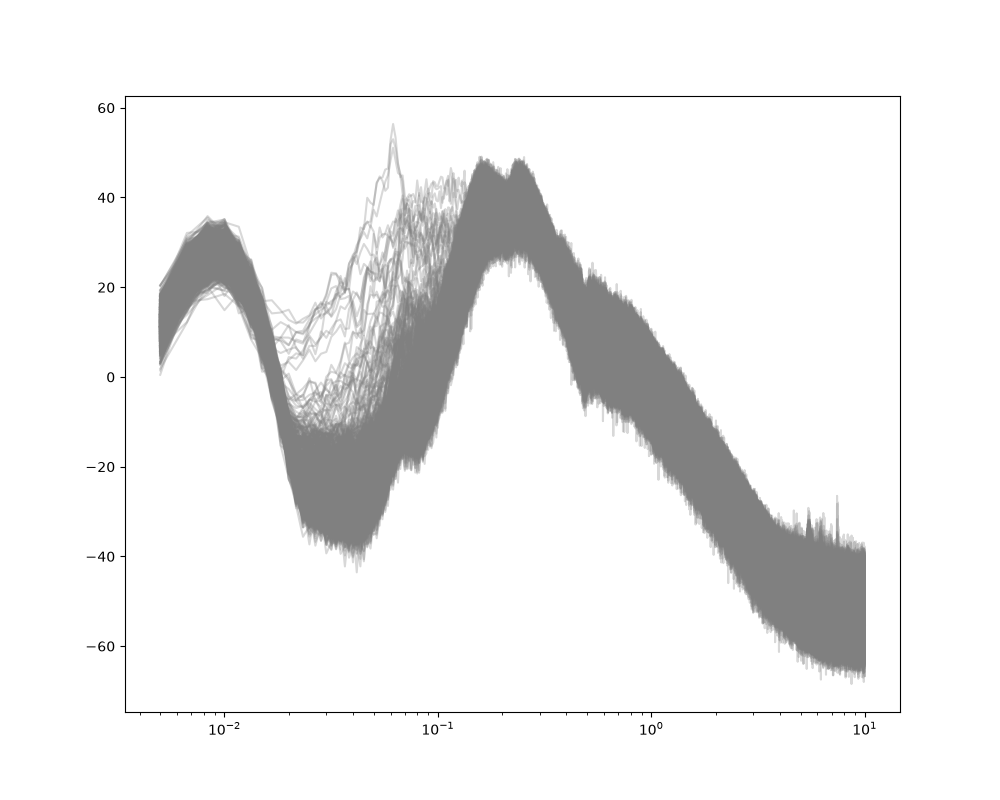

47984


In [32]:
# this the range of days data will be fetched for:
start_date = UTCDateTime("2020-07-01")
end_date = UTCDateTime("2020-07-25")

# for this example, we will look at a day within the range of days from above
# day_start_date = UTCDateTime("2020-07-21")
# day_end_date = UTCDateTime("2020-07-22")

stations = ["MM04","MM05","MM06"]
channels = ["CH3"] #,"CH1","CH2","CH3"]

# station = dataset.get_station("MM04")
# channel = station.get_channel("CH0")
# inventory = read_inventory(str(channel.response_file),format="RESP")

plt.figure(figsize=(10,8))

for station_idx in range(0,len(stations)):
    station = dataset.get_station(stations[station_idx])

    for channel_idx in range(0,len(channels)):
        channel = station.get_channel(channels[channel_idx])
        inventory = read_inventory(str(channel.response_file),format="RESP")

        # print(f"working on {stations[station_idx]} {channels[channel_idx]}")

        for day_idx in range(int((end_date - start_date) / 86400) + 1):
            day         = start_date + (day_idx         * 86400)
            day_before  = start_date + ((day_idx - 1)   * 86400)
            day_after   = start_date + ((day_idx + 1)   * 86400)

            # function to identify files
            waveform_files = channel.get_waveform_files(
                    starttime=day_before,
                    endtime=day_after)

            # create Obspy Stream object and merge the datasets
            stream = read(waveform_files[0])
            for file in waveform_files[1:]:
                stream += read(file)
                stream.merge(method=0, fill_value=None) # add some safety precautions here
                trace = stream[0]

            # stream.print_gaps() # use this to identify gaps in the data
            daily_data = extract_time_window(trace,starttime=day,endtime=day_after) 

            # remove instrument response (which automatically demeans data)
            # note on this: demean and RR at daily level, detrend at hourly level, psd at sub hourly level
            daily_data = remove_response(daily_data,inventory=inventory)

            for hour_idx in range(int((day_after-day)/ 3600)+1)[:-1]:
                hour        = day + (hour_idx * 3600)
                hour_after  = day + ((hour_idx+1) * 3600)

                hourly_data = extract_time_window(daily_data,starttime=hour,endtime=hour_after) 

                hourly_psds = []

                # print(f"working on {stations[station_idx]} {channels[channel_idx]} date {str(day)} hour {str(hour)}")


                for windowed_data in sliding_windows(hourly_data,window_minutes=10):

                    windowed_data.detrend("linear")
                    psd = calculate_psd(windowed_data,
                                sampling_rate=windowed_data.stats.sampling_rate,
                                min_frequency=0.005,
                                max_frequency=10.0)

                    frequency = psd[0]
                    hourly_psds.append(psd[1])
                
                hourly_psds = np.array(hourly_psds)
                median_psd = np.median(hourly_psds, axis=0)

                median_psd_db = 10*np.log10(median_psd)
                plt.semilogx(frequency,median_psd_db,c='grey',alpha=0.3)

plt.show()


print(median_psd.nbytes)


            

            